# Loading Dataset to Explore

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
BLUE, ORANGE, GRAY, LIGHT = "#2a78d6", "#eb6834", "#52514e", "#b4b2a9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#ecebe7", "axes.axisbelow": True, "axes.titleweight": "bold"})

print("Libraries Successfully Imported")

Libraries Successfully Imported


In [5]:
df = pd.read_csv('/Users/paolohalog/Desktop/Need4Data26/US_Accidents_March23_sampled_500k.csv')
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,...,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,...,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,...,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,...,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,...,False,False,False,False,False,False,Night,Night,Night,Night


In [7]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"].astype(str).str[:19], errors="coerce")
df["Year"] = df["Start_Time"].dt.year
df["High_Sev"] = (df["Severity"] >= 3).astype(int)
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight,Year,High_Sev
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,...,False,False,True,False,Day,Day,Day,Day,2019,0
1,A-4694324,Source1,2,2022-12-03 23:37:14,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,...,False,False,False,False,Night,Night,Night,Night,2022,0
2,A-5006183,Source1,2,2022-08-20 13:13:00,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,...,False,False,True,False,Day,Day,Day,Day,2022,0
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,...,False,False,False,False,Day,Day,Day,Day,2022,0
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,...,False,False,False,False,Night,Night,Night,Night,2020,0


# Findings 1: Dataset Details

In [8]:
# dataset shape
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")

Rows: 500,000 | Columns: 48


In [9]:
# dates of the data; timeline
print(f"Data from {df['Start_Time'].min().date()} to {df['Start_Time'].max().date()}")

Data from 2016-01-14 to 2023-03-31


In [10]:
# States within the dataset
print(f"States in the dataset: {df['State'].nunique()} | {df['State'].unique()}")

States in the dataset: 49 | <StringArray>
['LA', 'VA', 'CA', 'MN', 'MA', 'OR', 'FL', 'TX', 'IN', 'MT', 'AL', 'AZ', 'NY',
 'NC', 'SC', 'KS', 'MI', 'CO', 'GA', 'MD', 'IL', 'PA', 'NM', 'NV', 'NE', 'NJ',
 'TN', 'UT', 'RI', 'MS', 'IA', 'WA', 'MO', 'OH', 'OK', 'CT', 'DC', 'AR', 'WV',
 'KY', 'WI', 'NH', 'WY', 'DE', 'VT', 'ID', 'ME', 'ND', 'SD']
Length: 49, dtype: str


In [13]:
# share of each source providing the data
print((df['Source'].value_counts(normalize=True) * 100).round(2))

# while there is more data within source 1 the severity value in source 1 is more questionable than source 2
# since source 2 is more in line with the severity values of the other sources, we will focus on source 2 for our analysis

Source
Source1    55.92
Source2    42.81
Source3     1.27
Name: proportion, dtype: float64


# Finding 2: Definition of Severity

In [15]:
#distribution of severity throughout the sources
sev = df["Severity"].value_counts().sort_index()
print((sev / len(df) * 100).round(1)); print(f"High (3-4): {df['High_Sev'].mean()*100:.1f}%")

Severity
1     0.9
2    79.6
3    16.9
4     2.6
Name: count, dtype: float64
High (3-4): 19.5%


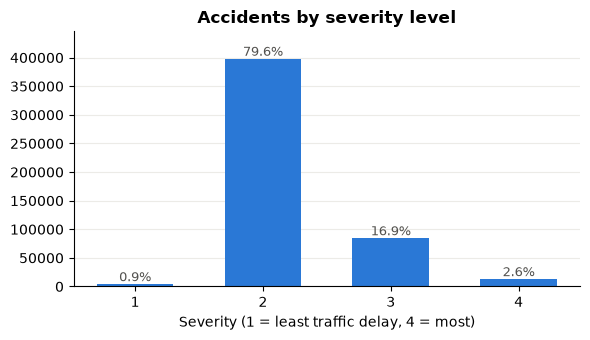

In [16]:
# visualzation of severity distribution
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(sev.index.astype(str), sev.values, color=BLUE, width=0.6)
for x, v in enumerate(sev.values):
    ax.text(x, v + 5000, f"{v/len(df)*100:.1f}%", ha="center", fontsize=9, color=GRAY)
ax.set_ylim(0, sev.max() * 1.12); ax.grid(axis="x", visible=False)
ax.set_title("Accidents by severity level"); ax.set_xlabel("Severity (1 = least traffic delay, 4 = most)")
plt.tight_layout(); 
plt.show()

# Findings 3: Source Definition of Severity Varies

In [18]:
# different accordances of severity so need to utilize one major source consistent with overall severity distribution
print((pd.crosstab(df["Source"], df["Severity"], normalize="index") * 100).round(1))

Severity    1     2     3    4
Source                        
Source1   0.6  91.2   3.8  4.3
Source2   1.0  64.9  33.6  0.4
Source3   4.4  64.7  30.8  0.1


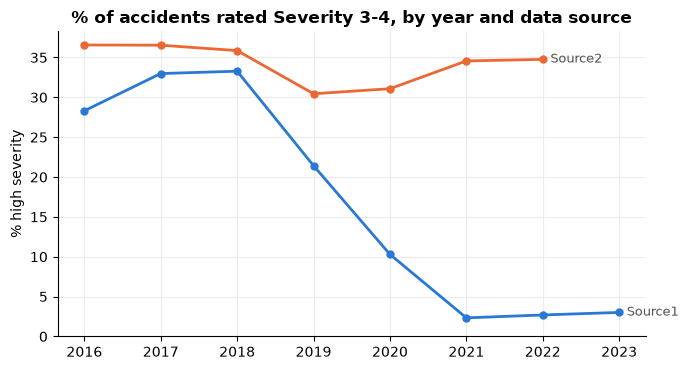

In [ ]:
# visual proof od consistency of severity distribution between source 1 and source 2
yr = (df[df["Source"].isin(["Source1", "Source2"])]
      .groupby(["Year", "Source"])["High_Sev"].mean().unstack() * 100)
fig, ax = plt.subplots(figsize=(7, 3.8))
for src, col in [("Source1", BLUE), ("Source2", ORANGE)]:
    s = yr[src].dropna()
    ax.plot(s.index, s.values, color=col, lw=2, marker="o", ms=5)
    ax.text(s.index[-1] + 0.1, s.values[-1], src, color=GRAY, va="center", fontsize=9)
ax.set_ylim(0, None); ax.set_ylabel("% high severity")
ax.set_title("% of accidents rated Severity 3-4, by year and data source")
plt.tight_layout(); 
plt.show()

# Findings 4: Significant Enough Values for Regional Distrubtion

In [21]:
# dividing the states into regions to analyze the data by region
regions = {"West": ["CA", "OR", "WA", "NV", "AZ", "UT", "CO", "ID", "MT", "WY", "NM"],
           "Midwest": ["IL", "IN", "MI", "OH", "WI", "MN", "IA", "MO", "KS", "NE", "SD", "ND"],
           "Northeast": ["NY", "NJ", "PA", "MA", "CT", "RI", "NH", "VT", "ME"],
           "South": ["TX", "FL", "GA", "NC", "SC", "VA", "TN", "AL", "LA", "KY", "MD", "OK",
                     "AR", "MS", "WV", "DE", "DC"]}

In [23]:
# distribution of accidents by region for source 2
s2 = df[df["Source"] == "Source2"].copy()
s2["Region"] = s2["State"].map({s: r for r, ss in regions.items() for s in ss})
reg = s2.groupby("Region").agg(accidents=("ID", "size"), states=("State", "nunique"),
                               pct_high=("High_Sev", "mean")).sort_values("accidents")
reg["pct_high"] = (reg["pct_high"] * 100).round(1)
print(reg)

           accidents  states  pct_high
Region                                
Northeast      26352       9      36.0
Midwest        28738      10      42.4
West           54628      11      37.9
South         104326      17      29.2


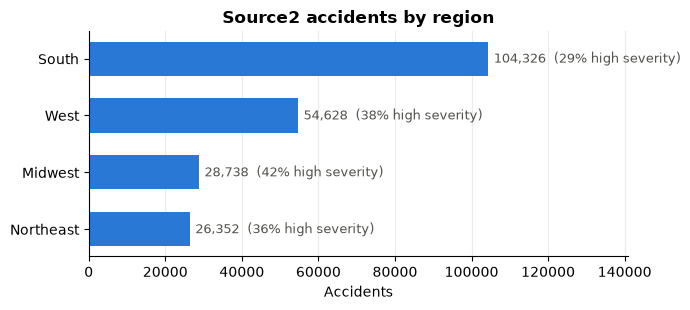

In [25]:
# visual representation of accidents by region for source 2
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(reg.index, reg["accidents"], color=BLUE, height=0.6)
for i, (n, p) in enumerate(zip(reg["accidents"], reg["pct_high"])):
    ax.text(n + 1500, i, f"{n:,}  ({p:.0f}% high severity)", va="center", fontsize=9, color=GRAY)
ax.set_xlim(0, reg["accidents"].max() * 1.35); ax.grid(axis="y", visible=False)
ax.set_title("Source2 accidents by region"); ax.set_xlabel("Accidents")
plt.tight_layout(); plt.show()